# Лабораторная работа № 1
## Первичная обработка одномерной выборки

**Студент:** Саббаг Райан  
**Вариант:** 20  
**Исходные данные:** файл `ПИН-27_ЛабПрак_26-27.xlsx`, лист `ЛР 1 и 2`, столбец `Вариант 20`.

В ноутбуке выполнены все пять пунктов задания: вариационный и статистический ряды, интервальная группировка на 7 разрядов, полигоны и гистограммы, эмпирические функции распределения исходной и сгруппированной выборок, а также точечные оценки характеристик.

**Важно:** массив исходных чисел включён прямо в код, поэтому при запуске не требуется отдельно загружать Excel-файл. Вычисления выполняются по формулам с полными исходными значениями; для таблиц результаты округляются до трёх знаков после запятой.

In [4]:
import math
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 180

# Точные исходные значения из Excel: "ЛР 1 и 2" -> "Вариант 20"
x = np.array([
    3.37735935692426, 11.2113721666362, 6.38592353912331,
    17.3872973530386, -3.9638092195475, 6.23701604646308,
    10.0608955549476, 10.273118188123, 25.9851402741546,
    -0.0313369390467662, 4.90962938760288, 5.9127880963353,
    9.00109070604046, 0.891058083162975, 11.4569675615699,
    13.9643530389389, 16.6139069118982, 9.08476201553696,
    11.3469191893421, -0.450041000251971, 10.0754652476507,
    11.1795803723745, 1.50737125041317, 4.94542932664408,
    10.3098606075877, 13.1135142713013, 10.0596428807768,
    2.30089591944556, -2.13656662748667, 1.66678367372008,
    22.0076665135695, 2.28198251792436, -3.60216186329049,
    7.7350274862433, 14.2983759839145, 5.7008426224115,
    -2.61532025979264, 6.55450212495812, 2.78600060417424,
    3.30859209765958, 14.7737064941538, 0.265274706367458,
    3.9934232475792, 1.19806098432187, 19.878481471012,
    -2.90489377114077, -11.0739868594745, -3.94400386828789,
    -2.36325392051582, -0.518884259183956
], dtype=float)

n = len(x)
x_sorted = np.sort(x)
assert n == 50

def fmt(z, digits=3):
    return f"{float(z):.{digits}f}".replace(".", ",")

def render_table(headers, rows, title=""):
    import html
    head = "".join(f"<th>{html.escape(str(h))}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{html.escape(str(v))}</td>" for v in row) + "</tr>" for row in rows)
    table = ("<h4>" + html.escape(title) + "</h4>" if title else "") + f"""<table style='border-collapse:collapse; font-size:13px'>
      <thead><tr style='background:#dce8f5'>{head}</tr></thead><tbody>{body}</tbody></table>"""
    table = table.replace("<th>","<th style='border:1px solid #b8c5d6;padding:5px 9px'>")
    table = table.replace("<td>","<td style='border:1px solid #b8c5d6;padding:4px 8px;text-align:center'>")
    display(HTML(table))

print(f"Вариант 20. Объём выборки n = {n}.")
print(f"Минимум: {fmt(x.min())}; максимум: {fmt(x.max())}")


Вариант 20. Объём выборки n = 50.
Минимум: -11,074; максимум: 25,985


### 1. Вариационный ряд, статистический ряд и размах

Вариационный ряд — элементы выборки в порядке возрастания. Статистический ряд — значения вариант и соответствующие частоты. Размах $R=x_{\max}-x_{\min}$.

In [5]:
R = x_sorted[-1] - x_sorted[0]
print("Вариационный ряд (50 значений):")
for i in range(0, n, 10):
    print("; ".join(fmt(v) for v in x_sorted[i:i+10]))
print("\nРазмах R = x_max - x_min =", fmt(R))
counts_raw = Counter(x_sorted)
render_table(
    ["№", "x_(i)", "n_i", "w_i"],
    [(i+1, fmt(v), counts_raw[v], fmt(counts_raw[v]/n)) for i,v in enumerate(sorted(counts_raw))],
    "Таблица 1. Статистический ряд исходной выборки"
)


Вариационный ряд (50 значений):
-11,074; -3,964; -3,944; -3,602; -2,905; -2,615; -2,363; -2,137; -0,519; -0,450
-0,031; 0,265; 0,891; 1,198; 1,507; 1,667; 2,282; 2,301; 2,786; 3,309
3,377; 3,993; 4,910; 4,945; 5,701; 5,913; 6,237; 6,386; 6,555; 7,735
9,001; 9,085; 10,060; 10,061; 10,075; 10,273; 10,310; 11,180; 11,211; 11,347
11,457; 13,114; 13,964; 14,298; 14,774; 16,614; 17,387; 19,878; 22,008; 25,985

Размах R = x_max - x_min = 37,059


№,x_(i),n_i,w_i
1,"-11,074",1,"0,020"
2,"-3,964",1,"0,020"
3,"-3,944",1,"0,020"
4,"-3,602",1,"0,020"
5,"-2,905",1,"0,020"
6,"-2,615",1,"0,020"
7,"-2,363",1,"0,020"
8,"-2,137",1,"0,020"
9,"-0,519",1,"0,020"
10,"-0,450",1,"0,020"


### 2. Эмпирическая функция распределения исходной выборки

Функция $F_n^*(t)=\frac{1}{n}\sum_{i=1}^n\mathbf{1}\{x_i\le t\}$ является ступенчатой и непрерывной справа. Каждое из 50 различных наблюдений увеличивает её на $1/50=0{,}020$. Закрашенная точка означает включённую левую границу, незакрашенная — исключённую правую.

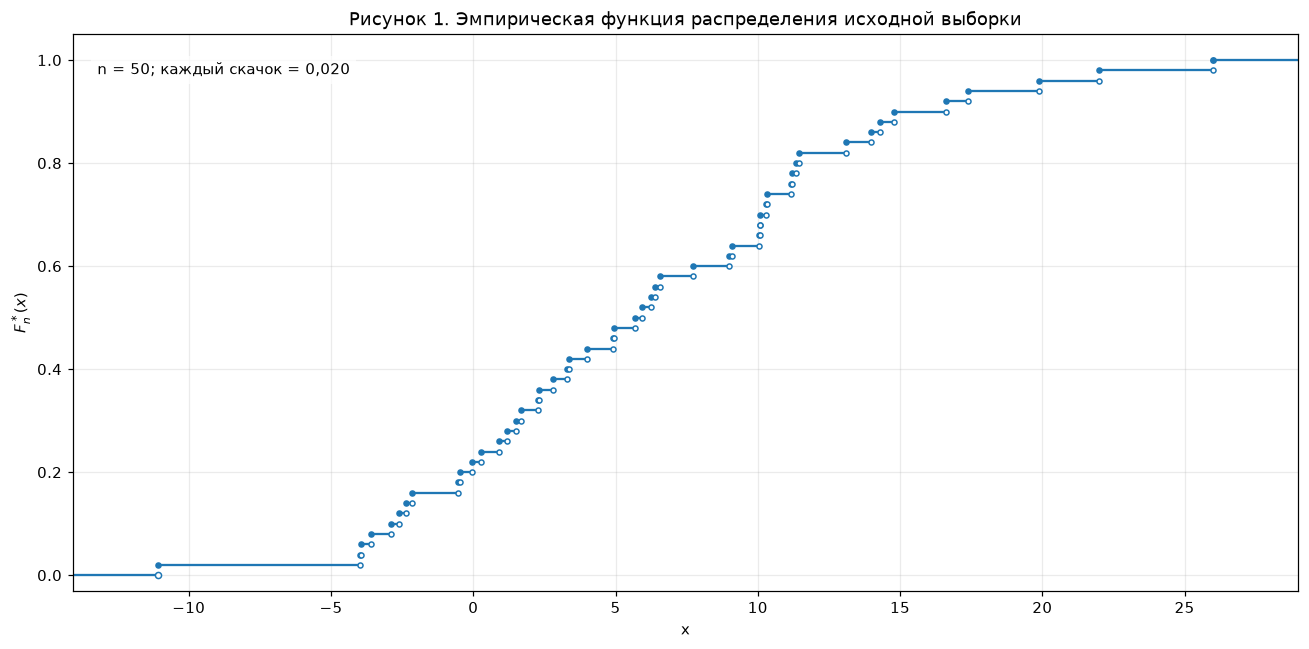

In [6]:
fig, ax = plt.subplots(figsize=(12,6))
xlo, xhi = x_sorted[0]-3, x_sorted[-1]+3
ax.hlines(0, xlo, x_sorted[0], color="tab:blue", lw=1.5)
ax.plot(x_sorted[0], 0, marker="o", mec="tab:blue", mfc="white", ms=4)
for i in range(n-1):
    y = (i+1)/n
    ax.hlines(y, x_sorted[i], x_sorted[i+1], color="tab:blue", lw=1.5)
    ax.plot(x_sorted[i], y, "o", color="tab:blue", ms=3.3)
    ax.plot(x_sorted[i+1], y, "o", mec="tab:blue", mfc="white", ms=3.3)
ax.hlines(1, x_sorted[-1], xhi, color="tab:blue", lw=1.5)
ax.plot(x_sorted[-1], 1, "o", color="tab:blue", ms=3.5)
ax.set(xlim=(xlo,xhi), ylim=(-0.03,1.05), xlabel="x", ylabel=r"$F_n^*(x)$",
       title="Рисунок 1. Эмпирическая функция распределения исходной выборки")
ax.text(0.02,0.95,"n = 50; каждый скачок = 0,020",transform=ax.transAxes,
        va="top",fontsize=10,bbox={"facecolor":"white","alpha":0.75,"edgecolor":"none"})
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("LR1_V20_Fig1_ECDF_raw.png", bbox_inches="tight")
plt.show()


### 3. Интервальный статистический ряд (7 одинаковых интервалов)

Число интервалов $k=7$, шаг группировки $\Delta=(x_{\max}-x_{\min})/7$. Границы вычисляются по исходным значениям без промежуточного округления. Последний интервал включает правую границу $x_{\max}$.

В книге середина интервала обозначена $z_i$; в тетради — $c_i$. Это одна и та же величина: $z_i=c_i=(a_i+b_i)/2$.

In [7]:
k = 7
Delta = R/k
edges = np.linspace(x_sorted[0], x_sorted[-1], k+1)
centers = (edges[:-1] + edges[1:]) / 2
n_i, _ = np.histogram(x, bins=edges)
w_i = n_i/n
h_i = n_i/Delta
h_i_rel = n_i/(n*Delta)
N_i = np.cumsum(n_i)
W_i = np.cumsum(w_i)

print("k =", k)
print("R =", fmt(R), "; Δ =", fmt(Delta))
rows = []
for i in range(k):
    interval = f"[{fmt(edges[i])}; {fmt(edges[i+1])}{']' if i==k-1 else ')'}"
    rows.append((i+1,interval,fmt(centers[i]),n_i[i],fmt(w_i[i]),fmt(h_i[i]),
                 fmt(h_i_rel[i]),int(N_i[i]),fmt(W_i[i])))
render_table(["i", "Интервал", "z_i = c_i", "n_i", "w_i", "n_i/Δ", "n_i/(nΔ)", "N_i", "W_i"],
             rows, "Таблица 2. Частоты интервально сгруппированной выборки")
print("Проверка: Σ n_i =", n_i.sum(), "; Σ w_i =", fmt(w_i.sum()))
print("Площадь гистограммы частот =", fmt((h_i*Delta).sum()))
print("Площадь гистограммы относительных частот =", fmt((h_i_rel*Delta).sum()))
assert n_i.tolist() == [1, 8, 13, 13, 10, 3, 2]
assert np.isclose(w_i.sum(),1)
assert N_i[-1] == n


k = 7
R = 37,059 ; Δ = 5,294


i,Интервал,z_i = c_i,n_i,w_i,n_i/Δ,n_i/(nΔ),N_i,W_i
1,"[-11,074; -5,780)","-8,427",1,"0,020","0,189","0,004",1,"0,020"
2,"[-5,780; -0,486)","-3,133",8,"0,160","1,511","0,030",9,"0,180"
3,"[-0,486; 4,808)","2,161",13,"0,260","2,456","0,049",22,"0,440"
4,"[4,808; 10,103)","7,456",13,"0,260","2,456","0,049",35,"0,700"
5,"[10,103; 15,397)","12,750",10,"0,200","1,889","0,038",45,"0,900"
6,"[15,397; 20,691)","18,044",3,"0,060","0,567","0,011",48,"0,960"
7,"[20,691; 25,985]","23,338",2,"0,040","0,378","0,008",50,"1,000"


Проверка: Σ n_i = 50 ; Σ w_i = 1,000
Площадь гистограммы частот = 50,000
Площадь гистограммы относительных частот = 1,000


### 4. Гистограммы и полигон частот

Высоты гистограмм: $h_i=n_i/\Delta$ и $h_i^{*}=n_i/(n\Delta)$. Для наглядности на левую гистограмму наложен полигон высот. На правом рисунке дополнительно изображена **гладкая нормальная плотность как иллюстративное сравнение**, а не установленный закон распределения генеральной совокупности. Проверка нормальности входит в ЛР №2.

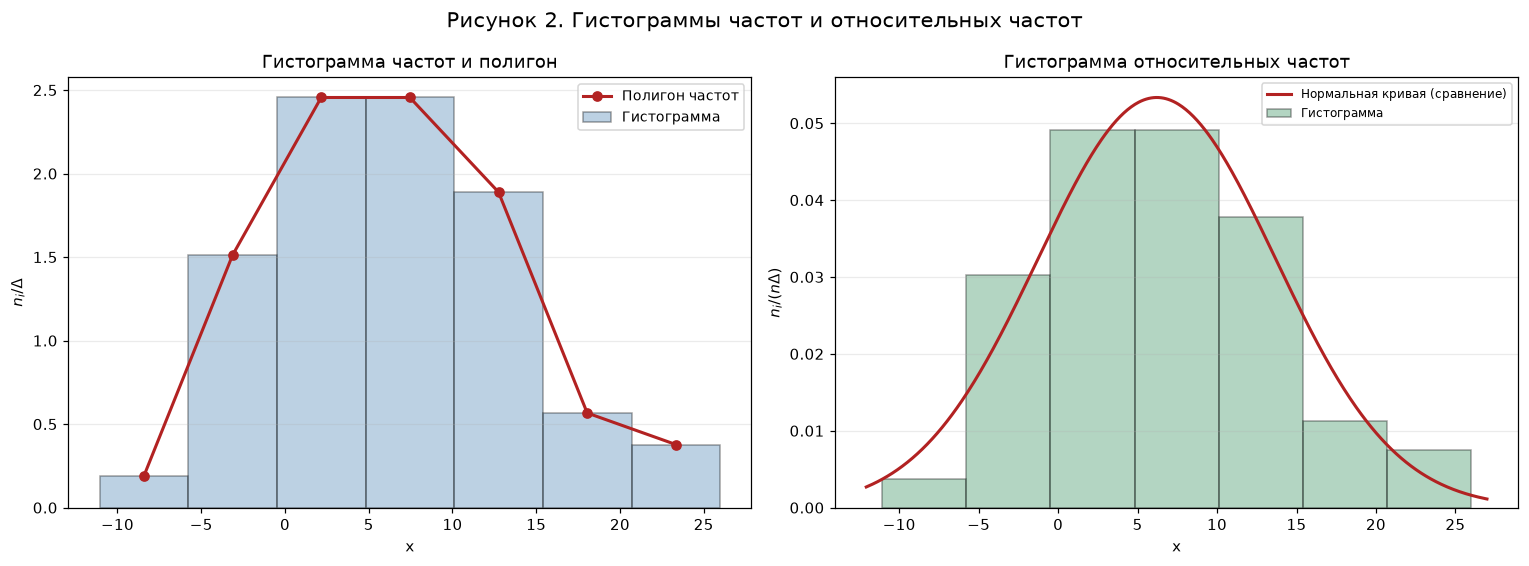

In [8]:
fig, axes = plt.subplots(1,2,figsize=(14,5.2))
ax = axes[0]
ax.bar(edges[:-1],h_i,width=Delta,align="edge",edgecolor="black",alpha=0.36,
       color="steelblue",label="Гистограмма")
ax.plot(centers,h_i,"o-",color="firebrick",lw=2,label="Полигон частот")
ax.set(xlabel="x",ylabel=r"$n_i/\Delta$",title="Гистограмма частот и полигон")
ax.grid(axis="y",alpha=0.25);ax.legend(fontsize=9)

ax = axes[1]
ax.bar(edges[:-1],h_i_rel,width=Delta,align="edge",edgecolor="black",alpha=0.36,
       color="seagreen",label="Гистограмма")
# Теоретическая кривая здесь — только для сравнения, не доказательство нормальности.
mean0 = sum(x)/n
sd0 = math.sqrt(sum((v-mean0)**2 for v in x)/(n-1))
xx = np.linspace(edges[0]-1,edges[-1]+1,500)
normal_curve = np.exp(-0.5*((xx-mean0)/sd0)**2)/(sd0*math.sqrt(2*math.pi))
ax.plot(xx,normal_curve,color="firebrick",lw=2,label="Нормальная кривая (сравнение)")
ax.set(xlabel="x",ylabel=r"$n_i/(n\Delta)$",title="Гистограмма относительных частот")
ax.grid(axis="y",alpha=0.25);ax.legend(fontsize=8)
fig.suptitle("Рисунок 2. Гистограммы частот и относительных частот",fontsize=14)
fig.tight_layout()
fig.savefig("LR1_V20_Fig2_Histograms.png", bbox_inches="tight")
plt.show()


### 5. Полигоны частот и относительных частот

Здесь для сравнения с отдельными рисунками в тетради показаны полигоны $n_i$ и $w_i$. Они имеют ту же форму, что и полигоны высот гистограмм, но отличаются масштабом по вертикали.

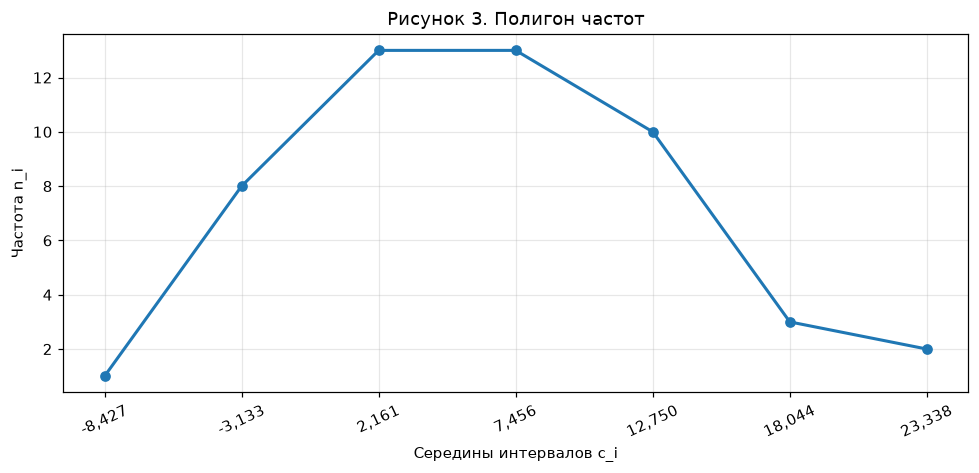

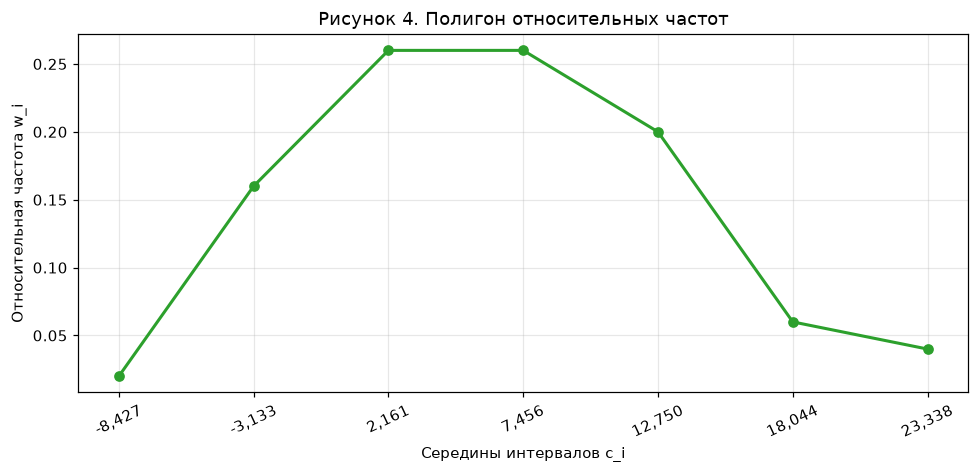

In [9]:
fig,ax=plt.subplots(figsize=(9,4.4))
ax.plot(centers,n_i,"o-",lw=2,markersize=6,color="tab:blue")
ax.set(xlabel="Середины интервалов c_i",ylabel="Частота n_i",
       title="Рисунок 3. Полигон частот")
ax.set_xticks(centers); ax.set_xticklabels([fmt(z) for z in centers],rotation=25)
ax.grid(alpha=0.3);fig.tight_layout()
fig.savefig("LR1_V20_Fig3_Frequency_polygon.png",bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(9,4.4))
ax.plot(centers,w_i,"o-",lw=2,markersize=6,color="tab:green")
ax.set(xlabel="Середины интервалов c_i",ylabel="Относительная частота w_i",
       title="Рисунок 4. Полигон относительных частот")
ax.set_xticks(centers); ax.set_xticklabels([fmt(z) for z in centers],rotation=25)
ax.grid(alpha=0.3);fig.tight_layout()
fig.savefig("LR1_V20_Fig4_Relative_polygon.png",bbox_inches="tight")
plt.show()


### 6. Эмпирическая функция распределения сгруппированной выборки

После замены наблюдений центрами интервалов получаем ступенчатую функцию $F_g^*(x)$, скачки которой равны $w_i$, а значения на ступенях — накопленным относительным частотам $W_i$. В точке $c_7$ функция уже равна 1.

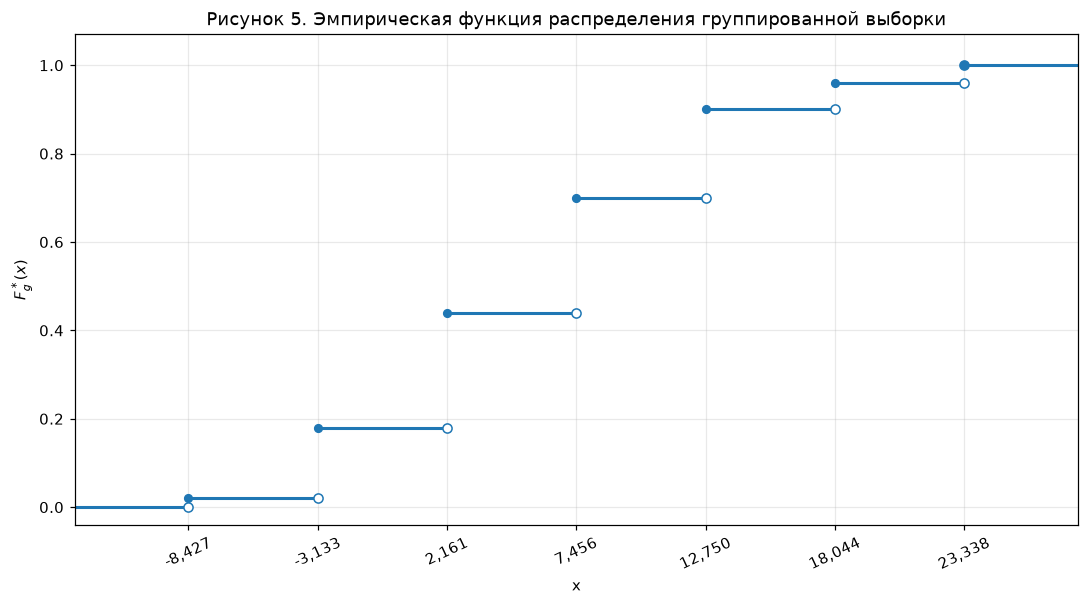

Последняя ступень: F_g*(x)=1 при x >= 23,338


In [10]:
fig,ax=plt.subplots(figsize=(10,5.6))
lo=edges[0]-2; hi=edges[-1]+2
ax.hlines(0,lo,centers[0],color="tab:blue",lw=2)
ax.plot(centers[0],0,"o",mec="tab:blue",mfc="white",ms=6)
for i in range(k-1):
    y = W_i[i]
    ax.hlines(y,centers[i],centers[i+1],color="tab:blue",lw=2)
    ax.plot(centers[i],y,"o",color="tab:blue",ms=5)
    ax.plot(centers[i+1],y,"o",mec="tab:blue",mfc="white",ms=6)
ax.hlines(1,centers[-1],hi,color="tab:blue",lw=2)
ax.plot(centers[-1],1,"o",color="tab:blue",ms=6)
ax.set(xlim=(lo,hi),ylim=(-0.04,1.07),xlabel="x",ylabel=r"$F_g^*(x)$",
       title="Рисунок 5. Эмпирическая функция распределения группированной выборки")
ax.set_xticks(centers);ax.set_xticklabels([fmt(z) for z in centers],rotation=25)
ax.grid(alpha=0.27);fig.tight_layout()
fig.savefig("LR1_V20_Fig5_ECDF_grouped.png",bbox_inches="tight")
plt.show()
print("Последняя ступень: F_g*(x)=1 при x >=",fmt(centers[-1]))


### 7. Точечные оценки для исходной выборки

Используем определения (без готовых функций для среднего и дисперсии):

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i,\quad D_{\mathrm{в}}=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2,\quad s^2=\frac{n}{n-1}D_{\mathrm{в}}.$$

При $n=50$ медиана — среднее арифметическое элементов $x_{(25)}$ и $x_{(26)}$. Мода отсутствует, если все наблюдения встречаются ровно по одному разу.

In [11]:
xbar = sum(x)/n
sumx2 = sum(v**2 for v in x)
D = sum((v-xbar)**2 for v in x)/n
s2 = sum((v-xbar)**2 for v in x)/(n-1)
s = math.sqrt(s2)
median = (x_sorted[n//2-1] + x_sorted[n//2])/2
unique_mode = [value for value,c in counts_raw.items() if c==max(counts_raw.values())]
mode_text = "Единственная мода отсутствует" if len(unique_mode)>1 else fmt(unique_mode[0])
print("Σ x_i =",fmt(sum(x)))
print("Σ x_i² =",fmt(sumx2))
print("x̄ =",fmt(xbar))
print("D_в =",fmt(D))
print("s² =",fmt(s2))
print("s =",fmt(s))
print("Me =",fmt(median),"(x_(25) =",fmt(x_sorted[24]),"; x_(26) =",fmt(x_sorted[25]),")")
print("Mo:",mode_text)


Σ x_i = 310,436
Σ x_i² = 4667,926
x̄ = 6,209
D_в = 54,810
s² = 55,929
s = 7,479
Me = 5,807 (x_(25) = 5,701 ; x_(26) = 5,913 )
Mo: Единственная мода отсутствует


### 8. Точечные оценки для интервально сгруппированной выборки

Для сгруппированного ряда используем центры интервалов $c_i$ и соответствующие частоты $n_i$. При расчёте медианы выполняем линейную интерполяцию внутри медианного интервала. Два смежных интервала имеют одинаковую максимальную частоту, поэтому оценка моды лежит на их общей границе.

In [12]:
xbar_g = sum(int(n_i[j])*centers[j] for j in range(k))/n
Dg = sum(int(n_i[j])*(centers[j]-xbar_g)**2 for j in range(k))/n
s2g = n/(n-1)*Dg
# Медианный интервал определяется по накопленным частотам
median_class = next(j for j,v in enumerate(N_i) if v >= n/2)
N_prev = int(N_i[median_class-1]) if median_class > 0 else 0
median_g = edges[median_class] + Delta*(n/2-N_prev)/n_i[median_class]
modal_indices = np.flatnonzero(n_i==n_i.max())
mode_g = edges[int(modal_indices[1])] # общая граница двух смежных модальных интервалов
print("Σ n_i*c_i =",fmt(sum(n_i*centers)))
print("Σ n_i*c_i² =",fmt(sum(n_i*(centers**2))))
print("x̄_g =",fmt(xbar_g))
print("D_g =",fmt(Dg))
print("s²_g =",fmt(s2g))
print("Me_g =",fmt(median_g))
print("Mo_g =",fmt(mode_g),"(граница двух модальных интервалов)")


Σ n_i*c_i = 319,837
Σ n_i*c_i² = 4624,506
x̄_g = 6,397
D_g = 51,572
s²_g = 52,624
Me_g = 6,030
Mo_g = 4,808 (граница двух модальных интервалов)


### 9. Сравнение точечных оценок и итоговые проверки

In [13]:
render_table(
    ["Характеристика", "Исходная выборка", "Группированная выборка"],
    [
      ("Выборочное среднее", fmt(xbar),fmt(xbar_g)),
      ("Выборочная дисперсия", fmt(D),fmt(Dg)),
      ("Исправленная дисперсия",fmt(s2),fmt(s2g)),
      ("Медиана",fmt(median),fmt(median_g)),
      ("Мода",mode_text,fmt(mode_g)),
    ],
    "Таблица 4. Сравнение оценок"
)
assert np.isclose(xbar,6.208716385720453)
assert np.isclose(D,54.810368784700586)
assert np.isclose(s2,55.9289477394904)
assert np.isclose(median,5.8068153593734)
assert np.isclose(xbar_g,6.396744503522074)
assert np.isclose(Dg,51.57177924873329)
assert np.isclose(s2g,52.62426453952376,atol=0.0002)
assert np.isclose(median_g,6.030226,atol=0.0001)
assert np.isclose(mode_g,4.808496199,atol=0.0001)
print("Проверки пройдены. Все результаты соответствуют варианту 20.")


Характеристика,Исходная выборка,Группированная выборка
Выборочное среднее,"6,209","6,397"
Выборочная дисперсия,"54,810","51,572"
Исправленная дисперсия,"55,929","52,624"
Медиана,"5,807","6,030"
Мода,Единственная мода отсутствует,"4,808"


Проверки пройдены. Все результаты соответствуют варианту 20.


### Вывод

В ходе лабораторной работы выполнена первичная статистическая обработка выборки объёма $n=50$. Построены вариационный и статистический ряды, интервальная таблица частот для семи равных интервалов, гистограммы и полигоны, а также эмпирические функции распределения исходной и сгруппированной выборок. Рассчитаны точечные оценки математического ожидания, выборочной и исправленной дисперсий, медианы и моды. Различия оценок для исходной и сгруппированной выборок объясняются заменой индивидуальных значений серединами интервалов. Результаты вычислений проверены численно.

**Файлы изображений** `LR1_V20_Fig1_...png` — `LR1_V20_Fig5_...png` сохраняются после выполнения кода в папку, из которой запускается ноутбук.

*График нормальной плотности на рисунке 2 приведён только для иллюстративного сравнения, а не для проверки гипотезы о нормальном распределении.*